<a href="https://colab.research.google.com/github/mdk-aarbi/tweet-sentiment-lstm/blob/main/notebook/twitter_sentiment_lstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tweet Sentiment with LSTMs: random embeddings vs frozen GloVe

Deep Learning course assignment. Task: classify English tweets as **negative, neutral or positive**.
Data: the public **TweetEval sentiment** benchmark (not collected by me).
Models: a bidirectional LSTM trained from scratch (Model A) and the same network with frozen GloVe Twitter 100d vectors (Model B).
Run top to bottom on a Colab runtime (GPU optional). Every number in the report and on the website is produced by this notebook.

In [ ]:
!pip -q install datasets gensim reportlab
import json, os, random, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from datasets import load_dataset

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
REPO = "tweet-sentiment-lstm"
for d in ["models", "results", "data"]:
    os.makedirs(f"{REPO}/{d}", exist_ok=True)

ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")
tr, va, te = [pd.DataFrame(ds[s]) for s in ["train", "validation", "test"]]
names = ["negative", "neutral", "positive"]
for n, d in [("train", tr), ("validation", va), ("test", te)]:
    print(n, len(d), d.label.value_counts(normalize=True).sort_index().round(4).to_dict())
BASE = float(te.label.value_counts(normalize=True).max())
print("majority-class baseline on test:", round(BASE, 4))
tr["n_words"] = tr.text.str.split().str.len()
print(tr.n_words.describe().round(1).to_dict())
print(tr.sample(5, random_state=SEED)[["text", "label"]].to_string())

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

train 45615 {0: 0.1555, 1: 0.4532, 2: 0.3913}
validation 2000 {0: 0.156, 1: 0.4345, 2: 0.4095}
test 12284 {0: 0.3233, 1: 0.4833, 2: 0.1933}
majority-class baseline on test: 0.4833
{'count': 45615.0, 'mean': 19.2, 'std': 4.9, 'min': 1.0, '25%': 16.0, '50%': 20.0, '75%': 23.0, 'max': 35.0}
                                                                                                                                       text  label
11449                                I forgot all about Ice Cube being in the movie First Sunday. I think I seen this shit in the theaters.      0
26433  playoffs are finally set. Chardon plays warren howland in the 1st round. if we win\u002c we play the winner of kenston v. tallmadge.      1
33669         Are we just going to ignore the fact that Ice Cube got his ass whoop by Ricky Smiley at the beginning of Friday After Next???      1
33013  If you live in the South Orlando area\u002c be on the lookout. @user has its 6th site opening on October 30th near t

## Preprocessing
Keras `TextVectorization`: lower-case, strip punctuation, split on whitespace, keep the 20,000 most frequent tokens, pad or cut to 50 tokens. The vocabulary is learned on the training set only.

In [ ]:
from tensorflow.keras import layers
MAXTOK, MAXLEN = 20000, 50
vec = layers.TextVectorization(max_tokens=MAXTOK, output_sequence_length=MAXLEN)
vec.adapt(tr.text.values)
Xtr, Xva, Xte = [vec(tf.constant(d.text.values)).numpy() for d in (tr, va, te)]
ytr, yva, yte = tr.label.values, va.label.values, te.label.values
vocab = vec.get_vocabulary()
print(len(vocab), vocab[:12], Xtr.shape)

20000 ['', '[UNK]', np.str_('the'), np.str_('to'), np.str_('user'), np.str_('in'), np.str_('on'), np.str_('a'), np.str_('and'), np.str_('i'), np.str_('of'), np.str_('for')] (45615, 50)


## Model A: BiLSTM with random embeddings
Embedding(20000, 100, mask) -> Bidirectional LSTM(64) -> Dropout(0.5) -> Dense(3, softmax). Adam 1e-3, batch 64, early stopping on validation loss (patience 3, best weights restored).

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

def build(emb_init="uniform", trainable=True):
    m = tf.keras.Sequential([
        layers.Input(shape=(MAXLEN,), dtype="int64"),
        layers.Embedding(MAXTOK, 100, mask_zero=True, embeddings_initializer=emb_init, trainable=trainable),
        layers.Bidirectional(layers.LSTM(64)),
        layers.Dropout(0.5),
        layers.Dense(3, activation="softmax")])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def fit(m):
    es = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    return m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=30, batch_size=64, callbacks=[es], verbose=2)

tf.keras.utils.set_random_seed(SEED)
mA = build()
mA.summary()
hA = fit(mA)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 100)        │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,084,867 (7.95 MB)

 Trainable params: 2,084,867 (7.95 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
713/713 - 23s - 33ms/step - accuracy: 0.6178 - loss: 0.8145 - val_accuracy: 0.6635 - val_loss: 0.7491
Epoch 2/30
713/713 - 7s - 10ms/step - accuracy: 0.7297 - loss: 0.6212 - val_accuracy: 0.6435 - val_loss: 0.7852
Epoch 3/30
713/713 - 7s - 10ms/step - accuracy: 0.8021 - loss: 0.4829 - val_accuracy: 0.6330 - val_loss: 0.9274
Epoch 4/30
713/713 - 7s - 10ms/step - accuracy: 0.8710 - loss: 0.3370 - val_accuracy: 0.6180 - val_loss: 1.1133


## Model B: the same network with frozen GloVe Twitter 100d vectors
Words found in GloVe get their pretrained vector, the rest get small random vectors. The embedding layer is frozen, so only the LSTM and the classifier learn.

In [ ]:
import gensim.downloader as api
glove = api.load("glove-twitter-100")
rng = np.random.default_rng(SEED)
G = rng.normal(0, 0.05, (MAXTOK, 100)).astype("float32")
hit = 0
for i, w in enumerate(vocab):
    if i > 1 and w in glove.key_to_index:
        G[i] = glove[w]; hit += 1
G[0] = 0
COVERAGE = hit / (len(vocab) - 2)
print("vocabulary with a GloVe vector: %.1f%%" % (100 * COVERAGE))
tf.keras.utils.set_random_seed(SEED)
mB = build(tf.keras.initializers.Constant(G), trainable=False)
hB = fit(mB)

[==================================================] 100.0% 387.1/387.1MB downloaded
vocabulary with a GloVe vector: 87.9%
Epoch 1/30
713/713 - 9s - 13ms/step - accuracy: 0.6056 - loss: 0.8232 - val_accuracy: 0.6370 - val_loss: 0.7934
Epoch 2/30
713/713 - 6s - 8ms/step - accuracy: 0.6509 - loss: 0.7516 - val_accuracy: 0.6520 - val_loss: 0.7551
Epoch 3/30
713/713 - 7s - 10ms/step - accuracy: 0.6640 - loss: 0.7255 - val_accuracy: 0.6600 - val_loss: 0.7425
Epoch 4/30
713/713 - 6s - 9ms/step - accuracy: 0.6771 - loss: 0.7040 - val_accuracy: 0.6600 - val_loss: 0.7438
Epoch 5/30
713/713 - 7s - 9ms/step - accuracy: 0.6852 - loss: 0.6869 - val_accuracy: 0.6630 - val_loss: 0.7446
Epoch 6/30
713/713 - 6s - 9ms/step - accuracy: 0.6961 - loss: 0.6666 - val_accuracy: 0.6570 - val_loss: 0.7429


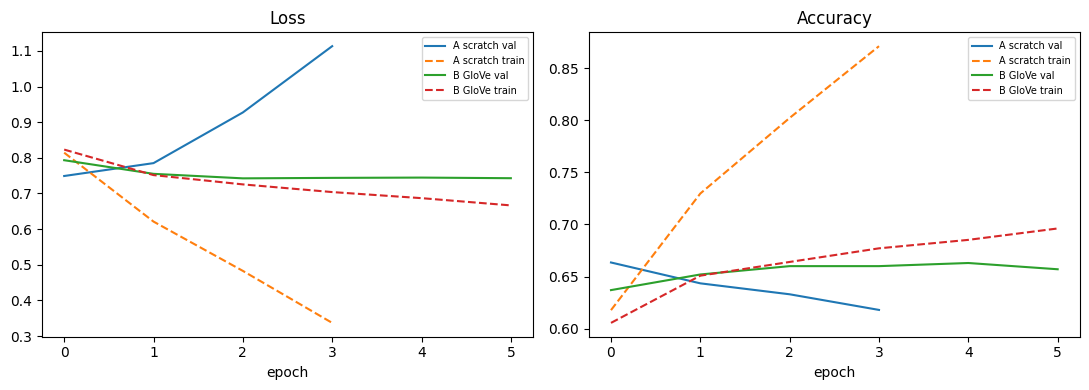

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, h in [("A scratch", hA), ("B GloVe", hB)]:
    ax[0].plot(h.history["val_loss"], label=name + " val"); ax[0].plot(h.history["loss"], "--", label=name + " train")
    ax[1].plot(h.history["val_accuracy"], label=name + " val"); ax[1].plot(h.history["accuracy"], "--", label=name + " train")
ax[0].set_title("Loss"); ax[1].set_title("Accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{REPO}/results/training_curves.png", dpi=150); plt.show()

## Evaluation on the untouched test set
Macro-F1 averages the three classes equally, so a model cannot hide behind the large neutral class.

A_scratch {'accuracy': 0.6101432758059264, 'macro_f1': 0.5935343710268831}
              precision    recall  f1-score   support

    negative      0.586     0.571     0.579      3972
     neutral      0.619     0.683     0.649      5937
    positive      0.630     0.492     0.553      2375

    accuracy                          0.610     12284
   macro avg      0.612     0.582     0.594     12284
weighted avg      0.610     0.610     0.608     12284

B_glove {'accuracy': 0.6372517095408662, 'macro_f1': 0.6256839141495133}
              precision    recall  f1-score   support

    negative      0.642     0.642     0.642      3972
     neutral      0.646     0.666     0.656      5937
    positive      0.603     0.556     0.579      2375

    accuracy                          0.637     12284
   macro avg      0.631     0.622     0.626     12284
weighted avg      0.637     0.637     0.637     12284

always-neutral baseline accuracy: 0.4833


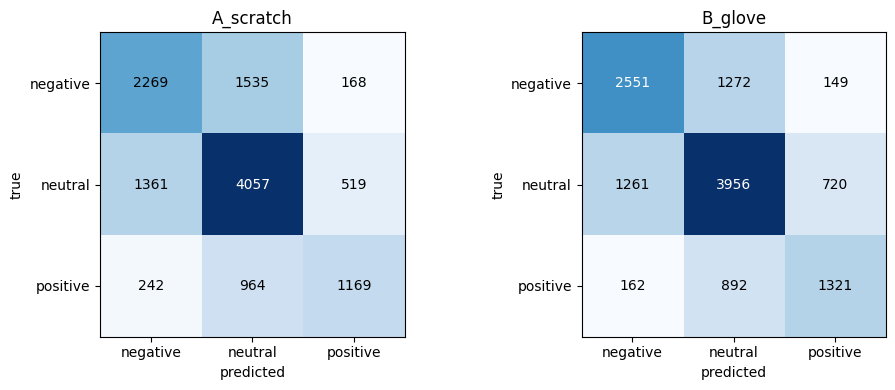

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
res = {"A_scratch": mA.predict(Xte, verbose=0).argmax(1), "B_glove": mB.predict(Xte, verbose=0).argmax(1)}
metrics, cms, reports = {}, {}, {}
for k, p in res.items():
    metrics[k] = {"accuracy": float((p == yte).mean()), "macro_f1": float(f1_score(yte, p, average="macro"))}
    cms[k] = confusion_matrix(yte, p).tolist()
    reports[k] = classification_report(yte, p, target_names=names, digits=3)
    print(k, metrics[k]); print(reports[k])
print("always-neutral baseline accuracy:", round(BASE, 4))
open(f"{REPO}/results/classification_reports.txt", "w").write("\n\n".join(k + "\n" + v for k, v in reports.items()))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (k, m) in zip(ax, cms.items()):
    a.imshow(m, cmap="Blues"); a.set_title(k); a.set_xticks(range(3)); a.set_yticks(range(3))
    a.set_xticklabels(names); a.set_yticklabels(names); a.set_xlabel("predicted"); a.set_ylabel("true")
    for i in range(3):
        for j in range(3): a.text(j, i, m[i][j], ha="center", va="center", color="white" if m[i][j] > 2500 else "black")
plt.tight_layout(); plt.savefig(f"{REPO}/results/confusion_matrices.png", dpi=150); plt.show()

## Error analysis (Model B)
Which mistakes does the best model make, and what do the wrong tweets look like?

In [ ]:
pB = res["B_glove"]; wrong = np.where(pB != yte)[0]
print(pd.crosstab(pd.Series(yte[wrong]).map(dict(enumerate(names))), pd.Series(pB[wrong]).map(dict(enumerate(names))), rownames=["true"], colnames=["predicted"]))
SHARE_TRUE_NEUTRAL = float((yte[wrong] == 1).mean()); SHARE_PRED_NEUTRAL = float((pB[wrong] == 1).mean())
print("errors: %d | true neutral: %.1f%% | predicted neutral: %.1f%%" % (len(wrong), 100 * SHARE_TRUE_NEUTRAL, 100 * SHARE_PRED_NEUTRAL))
pick = np.random.default_rng(SEED).choice(wrong, 12, replace=False)
lines = ["true=%-8s pred=%-8s | %s" % (names[yte[i]], names[pB[i]], te.text.iloc[i][:140].replace("\n", " ")) for i in pick]
print("\n".join(lines))
open(f"{REPO}/results/error_examples.txt", "w").write("\n".join(lines))

predicted  negative  neutral  positive
true                                  
negative          0     1272       149
neutral        1261        0       720
positive        162      892         0
errors: 4456 | true neutral: 44.5% | predicted neutral: 48.6%
true=negative pred=neutral  | As Soon As Mike Pence Posted This Photo, We Knew There Was Something Terribly Wrong. Do You See It?
true=negative pred=neutral  | Discover The Many Dangers Of Vaccines and Vaccination
true=negative pred=neutral  | A reminder to the leftists who kept calling for #1A for 8 yrs to be regulated and ban words bc who of who said it n…
true=neutral  pred=positive | Dear writers of westworld: Please make Dolores say more things like 'if out there is so great, why are you clamoring to get in here?'
true=negative pred=neutral  | The man who insanely claimed #BLM would team up with #ISIS is set to meet with Trump on Monday.
true=neutral  pred=negative | So youa ve saved for retirement. Did you think about these 3 t

1602

In [ ]:
mA.save(f"{REPO}/models/model_A_scratch.keras"); mB.save(f"{REPO}/models/model_B_glove.keras")
json.dump(vocab, open(f"{REPO}/models/vocab.json", "w"))
te.sample(100, random_state=SEED).assign(label_name=lambda d: d.label.map(dict(enumerate(names)))).to_csv(f"{REPO}/data/test_samples.csv", index=False)
print(sorted(os.listdir(f"{REPO}/models")))

['model_A_scratch.keras', 'model_B_glove.keras', 'vocab.json']


## Export for the browser
The trained Model B weights are exported to one binary file (embedding table quantised to int8 per row, LSTM and dense weights in float32). A numpy re-implementation of the forward pass is checked against Keras before the site uses it.

In [ ]:
Wt = mB.get_weights()
E, fK, fR, fb, bK, bR, bb, dW, db = Wt
print([w.shape for w in Wt])
sc = np.maximum(np.abs(E).max(1) / 127.0, 1e-8).astype("float32")
Eq = np.round(E / sc[:, None]).astype(np.int8)
Edeq = Eq.astype("float32") * sc[:, None]
sig = lambda x: 1 / (1 + np.exp(-x))

def lstm_run(x, K, R, b):
    U = R.shape[0]; h = np.zeros(U, "float32"); c = np.zeros(U, "float32")
    for xt in x:
        z = xt @ K + h @ R + b
        i, f, g, o = z[:U], z[U:2*U], z[2*U:3*U], z[3*U:]
        c = sig(f) * c + sig(i) * np.tanh(g); h = sig(o) * np.tanh(c)
    return h

def predict_np(ids, emb):
    ids = ids[ids != 0]
    if len(ids) == 0: return None
    x = emb[ids]
    z = np.concatenate([lstm_run(x, fK, fR, fb), lstm_run(x[::-1], bK, bR, bb)]) @ dW + db
    e = np.exp(z - z.max()); return e / e.sum()

n = 2000
kp = mB.predict(Xte[:n], verbose=0)
pf = np.array([predict_np(Xte[i], E) for i in range(n)]); pq = np.array([predict_np(Xte[i], Edeq) for i in range(n)])
EXPORT = {"max_prob_diff_keras_vs_numpy": float(np.abs(kp - pf).max()),
          "agreement_keras_vs_numpy": float((kp.argmax(1) == pf.argmax(1)).mean()),
          "agreement_keras_vs_int8": float((kp.argmax(1) == pq.argmax(1)).mean()),
          "accuracy_keras_first_%d" % n: float((kp.argmax(1) == yte[:n]).mean()),
          "accuracy_int8_first_%d" % n: float((pq.argmax(1) == yte[:n]).mean())}
print(EXPORT)

[(20000, 100), (100, 256), (64, 256), (256,), (100, 256), (64, 256), (256,), (128, 3), (3,)]
{'max_prob_diff_keras_vs_numpy': 2.384185791015625e-07, 'agreement_keras_vs_numpy': 1.0, 'agreement_keras_vs_int8': 0.9935, 'accuracy_keras_first_2000': 0.64, 'accuracy_int8_first_2000': 0.6415}


## Build the website and repository files
Writes the browser model (`weights.bin`, `manifest.json`, `vocab.json`), the page itself, and the files that make it easy for people and AI agents to read: `results.json`, `llms.txt`, `robots.txt`, `sitemap.xml`, `README.md`.
Fill the `LINKS` dictionary once the other deliverables exist and run this cell again.

In [ ]:
URL = "https://tweet-sentiment-lstm.vercel.app"
LINKS = {"github": "https://github.com/mdk-aarbi/tweet-sentiment-lstm", "report": "https://github.com/mdk-aarbi/tweet-sentiment-lstm/blob/main/Assignment_Report.pdf", "slides": "https://claude.ai/artifact/5FMzwoKnLn8Y2QHNqinDAq", "video": None, "dataset": "https://drive.google.com/file/d/1WandK1pMuvHDLzBgZ--LzfOS7Lv_BcaL/view?usp=drivesdk", "linkedin": None}

# ---- browser weights ----
arrs = [("emb_scale", sc), ("fK", fK), ("fR", fR), ("fb", fb), ("bK", bK), ("bR", bR), ("bb", bb), ("dW", dW), ("db", db)]
blob = Eq.tobytes(); man = {"emb_rows": int(Eq.shape[0]), "emb_dim": int(Eq.shape[1]), "units": int(fR.shape[0]), "arrays": {}}
for nm, a in arrs:
    a = np.ascontiguousarray(a, dtype="float32"); man["arrays"][nm] = {"offset": len(blob), "length": int(a.size)}; blob += a.tobytes()
open(f"{REPO}/weights.bin", "wb").write(blob)
json.dump(man, open(f"{REPO}/manifest.json", "w")); json.dump(vocab, open(f"{REPO}/vocab.json", "w"))

# ---- numbers used everywhere ----
mA_, mB_ = metrics["A_scratch"], metrics["B_glove"]
pct = lambda x: "%.2f%%" % (100 * x)
shares = te.label.value_counts(normalize=True).sort_index().tolist()
S = {"ACCA": pct(mA_["accuracy"]), "F1A": "%.4f" % mA_["macro_f1"], "ACCB": pct(mB_["accuracy"]), "F1B": "%.4f" % mB_["macro_f1"],
     "BASE": pct(BASE), "COV": "%.1f%%" % (100 * COVERAGE), "NTR": "{:,}".format(len(tr)), "NVA": "{:,}".format(len(va)), "NTE": "{:,}".format(len(te)),
     "SHG": "%.1f%%" % (100 * shares[0]), "SHN": "%.1f%%" % (100 * shares[1]), "SHP": "%.1f%%" % (100 * shares[2]),
     "WG": "%.2f" % (100 * shares[0]), "WN": "%.2f" % (100 * shares[1]), "WP": "%.2f" % (100 * shares[2]), "URL": URL, "NERR": "{:,}".format(len(wrong)),
     "TNE": "%.0f%%" % (100 * SHARE_TRUE_NEUTRAL), "PNE": "%.0f%%" % (100 * SHARE_PRED_NEUTRAL),
     "DACC": "%+.1f" % (100 * (mB_["accuracy"] - mA_["accuracy"])), "DF1": "%+.3f" % (mB_["macro_f1"] - mA_["macro_f1"])}
S["ERR"] = ("Model B made %s mistakes on the test set. %s of them were truly neutral tweets labelled positive or negative, and %s were positive or negative tweets predicted as neutral. "
            "The sampled examples show why: headlines and questions carrying charged topic words, and feelings that are implied rather than stated. The model reads words, not context, so it has no real handle on sarcasm, news framing or who a feeling is aimed at.") % (S["NERR"], S["TNE"], S["PNE"])
S["GAIN"] = "Frozen GloVe vectors changed accuracy by %s points and macro-F1 by %s compared with random embeddings. This comes from a single seeded run, so differences of a point or less should not be over-read." % (S["DACC"], S["DF1"])
def fill(t):
    for k, v in S.items(): t = t.replace("@@%s@@" % k, v)
    return t
results = {"assignment": "Tweet Sentiment LSTM", "task": "3-class tweet sentiment classification", "labels": names, "author": "Muhammad Danial Khalid",
    "institution": "Superior University, Lahore", "course": "Deep Learning", "date": "2026-11",
    "dataset": {"name": "TweetEval sentiment", "source": "https://huggingface.co/datasets/cardiffnlp/tweet_eval", "train": len(tr), "validation": len(va), "test": len(te),
                "test_class_share": {n_: round(s_, 4) for n_, s_ in zip(names, shares)}},
    "baseline_always_neutral_accuracy": round(BASE, 4), "glove_vocabulary_coverage": round(COVERAGE, 4),
    "models": {"A_bilstm_random_embeddings": {"test_accuracy": round(mA_["accuracy"], 4), "test_macro_f1": round(mA_["macro_f1"], 4), "confusion_matrix_rows_true_cols_predicted": cms["A_scratch"]},
               "B_bilstm_frozen_glove_twitter_100d": {"test_accuracy": round(mB_["accuracy"], 4), "test_macro_f1": round(mB_["macro_f1"], 4), "confusion_matrix_rows_true_cols_predicted": cms["B_glove"]}},
    "architecture": "TextVectorization(20000 tokens, 50 length) -> Embedding(20000,100,mask_zero) -> Bidirectional LSTM(64) -> Dropout(0.5) -> Dense(3, softmax). Model B embedding is GloVe Twitter 100d, frozen.",
    "browser_inference": "Pure JavaScript, int8-quantised embedding table, weights.bin about 2.4 MB, no server.", "export_check": EXPORT,
    "links": {k: v for k, v in LINKS.items() if v}, "demo": URL}
json.dump(results, open(f"{REPO}/results.json", "w"), indent=1); json.dump(results, open(f"{REPO}/results/results.json", "w"), indent=1)

# ---- page ----
ARROW = '<svg aria-hidden="true" width="14" height="14" viewBox="0 0 24 24" fill="none" stroke="#9BE3C0" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round"><path d="M7 17L17 7M8 7h9v9"/></svg>'
META = [("github", "GitHub repository", "Notebook, trained models, the browser demo and a README with the steps to reproduce the results.", "Open repository"),
        ("report", "Assignment report", "Problem, data, both architectures, training setup, results, error analysis and limitations.", "Read the report"),
        ("slides", "Presentation", "The slide deck for the class presentation, from task to results.", "View the slides"),
        ("video", "YouTube video", "A short walkthrough of the assignment and a live run of the demo.", "Watch the video"),
        ("dataset", "Full dataset", "The TweetEval sentiment splits used for training, validation and testing, as one zip.", "Download the zip"),
        ("linkedin", "LinkedIn post", "The short write-up of the assignment and its main lesson.", "See the post")]
btns = '<a class="btn" href="#demo">Try the live demo</a>'; cards = ""
for k, t, d, c in META:
    u = LINKS.get(k)
    if u:
        btns += '<a class="btn" href="%s" rel="noopener">%s%s</a>' % (u, t, ARROW)
        cards += '<article class="card"><h3>%s</h3><p>%s</p><a class="btn sm" href="%s" rel="noopener">%s%s</a></article>' % (t, d, u, c, ARROW)
cards += '<article class="card"><h3>Machine-readable results</h3><p>All numbers on this page as JSON: dataset sizes, both models, confusion matrices and architecture.</p><a class="btn sm" href="/results.json">Open results.json</a></article>'
cards += '<article class="card"><h3>llms.txt</h3><p>A plain-text summary of this assignment for AI assistants and agents, with every link and file.</p><a class="btn sm" href="/llms.txt">Open llms.txt</a></article>'
ld = {"@context": "https://schema.org", "@type": "WebApplication", "name": "Tweet Sentiment LSTM", "url": URL,
      "description": fill("Bidirectional LSTM that classifies tweets as positive, negative or neutral, trained on TweetEval. Runs entirely in the browser. Test accuracy @@ACCB@@, macro-F1 @@F1B@@."),
      "applicationCategory": "DeveloperApplication", "operatingSystem": "Any (web browser)", "inLanguage": "en",
      "author": {"@type": "Person", "name": "Muhammad Danial Khalid", "affiliation": {"@type": "CollegeOrUniversity", "name": "Superior University, Lahore"}},
      "isBasedOn": {"@type": "Dataset", "name": "TweetEval sentiment", "url": "https://huggingface.co/datasets/cardiffnlp/tweet_eval"},
      "offers": {"@type": "Offer", "price": "0", "priceCurrency": "USD"}, "sameAs": [v for v in LINKS.values() if v]}
def cm_html(name, m):
    h = '<table><caption>%s: confusion matrix on the test set (rows true, columns predicted)</caption><thead><tr><th scope="col">True / predicted</th>' % name
    h += "".join('<th scope="col">%s</th>' % r for r in names) + "</tr></thead><tbody>"
    for i, r in enumerate(names): h += '<tr><th scope="row">%s</th>' % r + "".join("<td>%d</td>" % v for v in m[i]) + "</tr>"
    return h + "</tbody></table>"

In [ ]:
PAGE = r"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Tweet Sentiment LSTM: positive, negative or neutral tweets, in your browser</title>
<meta name="description" content="Bidirectional LSTM tweet sentiment classifier (positive, negative, neutral) trained on TweetEval. Compares random embeddings with frozen GloVe Twitter vectors: @@ACCB@@ test accuracy, macro-F1 @@F1B@@. Runs fully in the browser.">
<meta name="author" content="Muhammad Danial Khalid">
<meta name="robots" content="index, follow">
<link rel="canonical" href="@@URL@@/">
<link rel="alternate" type="text/plain" href="/llms.txt" title="llms.txt">
<link rel="alternate" type="application/json" href="/results.json" title="results.json">
<meta property="og:type" content="website">
<meta property="og:title" content="Tweet Sentiment LSTM">
<meta property="og:description" content="Two LSTMs, one tweet: random vs GloVe embeddings on TweetEval. Try it in your browser.">
<meta property="og:url" content="@@URL@@/">
<meta name="twitter:card" content="summary">
<script type="application/ld+json">@@LD@@</script>
<style>
*{box-sizing:border-box}body{margin:0;background:#141815;color:#EDEDE6;font:16px/1.65 Inter,system-ui,-apple-system,Segoe UI,Roboto,sans-serif}
.w{max-width:1152px;margin:0 auto;padding:0 24px}section{padding-top:64px}h1,h2,h3{font-family:"Space Grotesk",Inter,system-ui,sans-serif;letter-spacing:-.01em;margin:0}
h1{font-size:clamp(34px,6vw,60px);line-height:1.08;max-width:900px}h2{font-size:clamp(26px,4vw,36px);margin-bottom:10px}h3{font-size:21px;margin-bottom:8px}
p{margin:0 0 12px;color:#A3A89F}.eyebrow{font-size:13px;letter-spacing:.12em;text-transform:uppercase;color:#9BE3C0;font-weight:600;margin:64px 0 20px}
.lead{font-size:19px;max-width:760px;margin:22px 0}.row{display:flex;flex-wrap:wrap;gap:12px}
.btn{display:inline-flex;align-items:center;gap:8px;min-height:48px;padding:0 22px;border-radius:12px;background:#1B201C;border:1px solid #2F3731;color:#EDEDE6;font:500 16px Inter,system-ui,sans-serif;text-decoration:none;cursor:pointer}
.btn:hover{background:#262d28;border-color:#4a5a4f}.btn.sm{min-height:44px;font-size:15px;padding:0 18px}.btn:focus-visible,button:focus-visible,textarea:focus-visible{outline:2px solid #9BE3C0;outline-offset:2px}
.go{background:#9BE3C0;color:#0F1411;font-weight:600;border-color:#9BE3C0}.go:hover{background:#b6efd2}
hr{border:0;border-top:1px solid #2A312C;margin:36px 0 0}.panel,.card{background:#1B201C;border:1px solid #2A312C;border-radius:16px;padding:24px}
.demo{display:flex;flex-wrap:wrap;gap:32px;padding:28px}.demo>div{flex:1 1 320px;min-width:0}
label{display:block;font-size:14px;font-weight:600;color:#A3A89F;margin-bottom:8px}
textarea{width:100%;background:#141815;border:1px solid #2F3731;border-radius:12px;padding:16px;color:#EDEDE6;font:17px/1.5 Inter,system-ui,sans-serif;resize:vertical}
.chip{min-height:44px;padding:0 16px;border-radius:999px;background:transparent;border:1px solid #2F3731;color:#A3A89F;font:14px Inter,system-ui,sans-serif;cursor:pointer}.chip:hover{border-color:#4a5a4f;color:#EDEDE6}
.bar{margin-bottom:16px}.bar .l{display:flex;justify-content:space-between;font-size:15px}.bar .t{height:12px;border-radius:6px;background:#262d28;margin-top:6px}.bar .f{height:12px;border-radius:6px;width:0;transition:width .3s}
#verdict{font:700 26px "Space Grotesk",sans-serif;margin:0 0 18px;min-height:34px;color:#EDEDE6}
.grid{display:flex;flex-wrap:wrap;gap:16px}.grid>*{flex:1 1 300px;min-width:0}.num{font:700 40px "Space Grotesk",sans-serif;color:#9BE3C0;line-height:1.2}
.split{display:flex;height:18px;border-radius:9px;overflow:hidden;margin:12px 0}.tw{overflow-x:auto}
table{width:100%;border-collapse:collapse;font-size:15px}caption{text-align:left;color:#A3A89F;padding:0 0 10px;font-size:14px}th,td{padding:12px 16px;text-align:left;border-top:1px solid #2A312C}thead th{color:#A3A89F;font-weight:600;border-top:0}tr.best td,tr.best th{background:#202722;font-weight:600}
.tag{font-size:13px;letter-spacing:.1em;text-transform:uppercase;font-weight:600}footer{margin-top:72px;padding:28px 0 48px;border-top:1px solid #2A312C;font-size:14px;color:#A3A89F}
a{color:#9BE3C0}.btn,.btn:hover{text-decoration:none}
</style>
</head>
<body>
<header class="w">
<p class="eyebrow">Deep Learning assignment · Twitter text · RNN / LSTM</p>
<h1>Positive, negative or neutral? Two LSTMs, one tweet.</h1>
<p class="lead">A sentiment classifier for tweets: a bidirectional LSTM trained from scratch, and the same network with frozen GloVe Twitter word vectors, compared on the public TweetEval benchmark. The model runs directly in your browser, so your text never leaves your device.</p>
<nav class="row" aria-label="Assignment links">@@BTNS@@</nav>
<hr>
</header>
<main class="w">
<section id="demo" aria-labelledby="h-demo">
<h2 id="h-demo">Try it on your own tweet</h2>
<p>Type or paste a tweet. The model returns a probability for each class. It works best on English tweets.</p>
<form class="panel demo" id="f" onsubmit="return false">
<div>
<label for="tw">Tweet</label>
<textarea id="tw" name="tweet" rows="4" maxlength="400">Just landed in Lahore and the weather is perfect, best trip so far!</textarea>
<div class="row" style="margin-top:14px;align-items:center">
<button class="btn go" id="go" type="submit">Analyze</button>
<button class="chip" type="button" data-t="Just landed in Lahore and the weather is perfect, best trip so far!">Example: positive</button>
<button class="chip" type="button" data-t="Two hours late again and nobody at the airline desk will even look at us. Awful service.">Example: negative</button>
<button class="chip" type="button" data-t="The match starts at 7pm on Saturday at the national stadium.">Example: neutral</button>
</div>
</div>
<div role="status" aria-live="polite">
<p id="verdict">Loading model (2.4 MB)...</p>
<div class="bar"><div class="l"><span>Positive</span><span id="vp">0%</span></div><div class="t"><div class="f" id="bp" style="background:#7BC9A0"></div></div></div>
<div class="bar"><div class="l"><span>Neutral</span><span id="vn">0%</span></div><div class="t"><div class="f" id="bn" style="background:#8FA9C4"></div></div></div>
<div class="bar"><div class="l"><span>Negative</span><span id="vg">0%</span></div><div class="t"><div class="f" id="bg" style="background:#E8896B"></div></div></div>
</div>
</form>
<noscript><p>This demo needs JavaScript. All results are also listed below and in <a href="/results.json">results.json</a>.</p></noscript>
</section>
<section id="data" aria-labelledby="h-data">
<h2 id="h-data">The data</h2>
<p>TweetEval sentiment is a public benchmark of English tweets labelled positive, negative or neutral. I did not collect it myself. I used the official splits and kept the test set untouched until the final evaluation.</p>
<div class="grid">
<div class="card"><div class="num">@@NTR@@</div>training tweets</div>
<div class="card"><div class="num">@@NVA@@</div>validation tweets</div>
<div class="card"><div class="num">@@NTE@@</div>test tweets, never seen in training</div>
</div>
<div class="panel" style="margin-top:16px">
<strong>Test set class balance</strong>
<div class="split" role="img" aria-label="Test set: neutral @@SHN@@, negative @@SHG@@, positive @@SHP@@"><div style="width:@@WN@@%;background:#8FA9C4"></div><div style="width:@@WG@@%;background:#E8896B"></div><div style="width:@@WP@@%;background:#7BC9A0"></div></div>
<p>Neutral @@SHN@@ · Negative @@SHG@@ · Positive @@SHP@@. Always guessing "neutral" already scores @@BASE@@, so any model has to beat that to be useful.</p>
</div>
</section>
<section id="models" aria-labelledby="h-models">
<h2 id="h-models">Two models, same data</h2>
<div class="grid">
<article class="card"><div class="tag" style="color:#E8896B">Model A · from scratch</div><h3>BiLSTM, random embeddings</h3><p>Embedding (20,000 words, 100 dimensions, learned from zero), bidirectional LSTM with 64 units, dropout 0.5, softmax over 3 classes. Early stopping on validation loss.</p></article>
<article class="card"><div class="tag" style="color:#7BC9A0">Model B · pretrained vectors</div><h3>BiLSTM, frozen GloVe Twitter</h3><p>The same network, but the embedding layer is initialised from GloVe Twitter 100d and frozen. @@COV@@ of the vocabulary has a pretrained vector.</p></article>
</div>
</section>
<section id="results" aria-labelledby="h-res">
<h2 id="h-res">Results on the unseen test set</h2>
<p>Macro-F1 averages the three classes equally, so a model cannot hide behind the big neutral class.</p>
<div class="panel tw"><table><caption>Test set results (@@NTE@@ tweets)</caption>
<thead><tr><th scope="col">Model</th><th scope="col">Accuracy</th><th scope="col">Macro-F1</th></tr></thead>
<tbody>
<tr><th scope="row">Always guess neutral</th><td>@@BASE@@</td><td>n/a</td></tr>
<tr><th scope="row">A: BiLSTM from scratch</th><td>@@ACCA@@</td><td>@@F1A@@</td></tr>
<tr class="best"><th scope="row">B: BiLSTM + frozen GloVe</th><td>@@ACCB@@</td><td>@@F1B@@</td></tr>
</tbody></table></div>
<div class="grid" style="margin-top:16px">
<div class="panel tw">@@CMA@@</div>
<div class="panel tw">@@CMB@@</div>
</div>
<div class="panel" style="margin-top:16px"><h3>Where the model gets it wrong</h3>
<p>@@ERR@@</p>
<p>@@GAIN@@</p></div>
</section>
<section id="resources" aria-labelledby="h-res2">
<h2 id="h-res2">Everything in one place</h2>
<div class="grid">@@CARDS@@</div>
</section>
</main>
<footer><div class="w"><div class="row" style="justify-content:space-between"><span>Muhammad Danial Khalid · BSCS, Superior University, Lahore</span><span>Deep Learning course · November 2026</span></div></div></footer>
<script type="application/json" id="results-data">@@RJ@@</script>
<script>
(function(){
const PUNCT=/[!"#$%&'()*+,\-./:;<=>?@\[\\\]^_\x60{|}~]/g;
const $=id=>document.getElementById(id);let M=null;
const sg=x=>1/(1+Math.exp(-x));
function tok(t){return t.toLowerCase().replace(PUNCT,"").split(/\s+/).filter(Boolean).slice(0,50)}
function run(ids,K,Rr,b){const U=M.U,D=M.D,G=4*U;const h=new Float32Array(U),c=new Float32Array(U),x=new Float32Array(D),z=new Float32Array(G);
for(const id of ids){const s=M.sc[id],base=id*D;for(let i=0;i<D;i++)x[i]=M.emb[base+i]*s;for(let j=0;j<G;j++)z[j]=b[j];
for(let i=0;i<D;i++){const xv=x[i],o=i*G;for(let j=0;j<G;j++)z[j]+=xv*K[o+j]}
for(let k=0;k<U;k++){const hv=h[k],o=k*G;for(let j=0;j<G;j++)z[j]+=hv*Rr[o+j]}
for(let k=0;k<U;k++){const ig=sg(z[k]),fg=sg(z[U+k]),gg=Math.tanh(z[2*U+k]),og=sg(z[3*U+k]);c[k]=fg*c[k]+ig*gg;h[k]=og*Math.tanh(c[k])}}
return h}
function predict(text){const ids=tok(text).map(w=>M.idx.has(w)?M.idx.get(w):1);if(!ids.length)return null;
const hf=run(ids,M.fK,M.fR,M.fb),hb=run(ids.slice().reverse(),M.bK,M.bR,M.bb);const h=Array.from(hf).concat(Array.from(hb));
const z=[0,1,2].map(k=>{let s=M.db[k];for(let i=0;i<h.length;i++)s+=h[i]*M.dW[i*3+k];return s});
const m=Math.max(z[0],z[1],z[2]),e=z.map(v=>Math.exp(v-m)),t=e[0]+e[1]+e[2];return e.map(v=>v/t)}
function show(p){const names=["Negative","Neutral","Positive"],ids=["bg","bn","bp"],vs=["vg","vn","vp"];
if(!p){$("verdict").textContent="Type a tweet first.";return}
p.forEach((v,i)=>{$(ids[i]).style.width=(v*100).toFixed(1)+"%";$(vs[i]).textContent=(v*100).toFixed(1)+"%"});
const k=p.indexOf(Math.max(p[0],p[1],p[2]));$("verdict").textContent=names[k]}
function go(){if(M)show(predict($("tw").value))}
async function load(){const man=await fetch("manifest.json").then(r=>r.json());
const r=await Promise.all([fetch("vocab.json").then(r=>r.json()),fetch("weights.bin").then(r=>r.arrayBuffer())]);const vocab=r[0],buf=r[1];
const R=man.emb_rows,D=man.emb_dim;const f=n=>new Float32Array(buf,man.arrays[n].offset,man.arrays[n].length);
const idx=new Map();vocab.forEach((w,i)=>{if(!idx.has(w))idx.set(w,i)});
M={idx:idx,emb:new Int8Array(buf,0,R*D),sc:f("emb_scale"),fK:f("fK"),fR:f("fR"),fb:f("fb"),bK:f("bK"),bR:f("bR"),bb:f("bb"),dW:f("dW"),db:f("db"),D:D};M.U=M.dW.length/6;
window.__predict=function(t){const p=predict(t);return p&&{negative:p[0],neutral:p[1],positive:p[2]}};window.__ready=true;go()}
$("f").addEventListener("submit",go);$("go").addEventListener("click",go);
document.querySelectorAll(".chip").forEach(b=>b.addEventListener("click",()=>{$("tw").value=b.dataset.t;go()}));
load().catch(e=>{$("verdict").textContent="Could not load the model: "+e.message});
})();
</script>
</body>
</html>"""
page = fill(PAGE.replace("@@LD@@", json.dumps(ld)).replace("@@BTNS@@", btns).replace("@@CARDS@@", cards)
            .replace("@@CMA@@", cm_html("Model A", cms["A_scratch"])).replace("@@CMB@@", cm_html("Model B", cms["B_glove"])).replace("@@RJ@@", json.dumps(results)))
open(f"{REPO}/index.html", "w").write(page)

lk = "\n".join("- %s: %s" % (k, v) for k, v in LINKS.items() if v) or "- (other links are added here when published)"
open(f"{REPO}/llms.txt", "w").write(fill("""# Tweet Sentiment LSTM

> A bidirectional LSTM that classifies English tweets as positive, negative or neutral. Trained on the public TweetEval sentiment benchmark. Compares random embeddings (Model A) with frozen GloVe Twitter 100d embeddings (Model B). Runs entirely in the browser with no server. University assignment for a Deep Learning course by Muhammad Danial Khalid, BSCS, Superior University, Lahore (November 2026).

## Results (test set, @@NTE@@ tweets)
- Always guess neutral: accuracy @@BASE@@
- Model A, BiLSTM random embeddings: accuracy @@ACCA@@, macro-F1 @@F1A@@
- Model B, BiLSTM frozen GloVe Twitter: accuracy @@ACCB@@, macro-F1 @@F1B@@

## Data
- TweetEval sentiment (cardiffnlp/tweet_eval): @@NTR@@ train, @@NVA@@ validation, @@NTE@@ test. Labels: negative, neutral, positive. Not collected by the author.

## Model
- TextVectorization (20,000 tokens, length 50) -> Embedding(20000,100) -> Bidirectional LSTM(64) -> Dropout(0.5) -> Dense(3, softmax).
- Browser inference in plain JavaScript: weights.bin (about 2.4 MB, int8-quantised embeddings), manifest.json, vocab.json.

## Links
- Live demo: @@URL@@/
- Machine-readable results: @@URL@@/results.json
""") + lk + """

## How to query the model from a page
After the page loads, window.__ready is true and window.__predict("some tweet") returns {negative, neutral, positive} probabilities.
""")
open(f"{REPO}/robots.txt", "w").write("User-agent: *\nAllow: /\n\nSitemap: %s/sitemap.xml\n" % URL)
open(f"{REPO}/sitemap.xml", "w").write('<?xml version="1.0" encoding="UTF-8"?>\n<urlset xmlns="http://www.sitemaps.org/schemas/sitemap/0.9">\n<url><loc>%s/</loc></url>\n<url><loc>%s/llms.txt</loc></url>\n<url><loc>%s/results.json</loc></url>\n</urlset>\n' % (URL, URL, URL))
open(f"{REPO}/.vercelignore", "w").write("models/\ndata/\nnotebook/\nresults/\nAssignment_Report.pdf\npredict.py\nrequirements.txt\nREADME.md\n")
open(f"{REPO}/requirements.txt", "w").write("tensorflow>=2.15\nnumpy\n")
open(f"{REPO}/predict.py", "w").write('''"""Predict tweet sentiment with the trained BiLSTM + GloVe model.

Usage: python predict.py "your tweet here"
"""
import json, sys
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

NAMES = ["negative", "neutral", "positive"]
vocab = json.load(open("models/vocab.json"))
vec = layers.TextVectorization(max_tokens=20000, output_sequence_length=50, vocabulary=vocab)
model = tf.keras.models.load_model("models/model_B_glove.keras")

text = " ".join(sys.argv[1:]) or "I love this so much!"
p = model.predict(vec(tf.constant([text])), verbose=0)[0]
for n, v in sorted(zip(NAMES, p), key=lambda t: -t[1]):
    print("%-9s %.3f" % (n, v))
''')
print(sorted(os.listdir(REPO)), len(page))

['.git', '.vercelignore', 'Project_Report.pdf', 'README.md', 'data', 'index.html', 'llms.txt', 'manifest.json', 'models', 'predict.py', 'requirements.txt', 'results', 'results.json', 'robots.txt', 'sitemap.xml', 'vocab.json', 'weights.bin'] 20640


## README and dataset archive

In [ ]:
rows = "\n".join("- %s: %s" % (t, LINKS[k]) for k, t, _, _ in META if LINKS.get(k)) or "- (added when published)"
README = fill("""# Tweet Sentiment LSTM

Three-class tweet sentiment analysis (negative, neutral, positive) with LSTMs. Deep Learning course assignment, Superior University, Lahore.
A bidirectional LSTM trained from scratch (Model A) is compared with the same network using frozen GloVe Twitter 100d embeddings (Model B).
The trained model also runs in the browser: **@@URL@@**

## Results on the TweetEval test set (@@NTE@@ tweets)

| Model | Accuracy | Macro-F1 |
|---|---|---|
| Always guess neutral | @@BASE@@ | n/a |
| A: BiLSTM, random embeddings | @@ACCA@@ | @@F1A@@ |
| B: BiLSTM, frozen GloVe Twitter | @@ACCB@@ | @@F1B@@ |

Single seeded run (seed 42). Confusion matrices, training curves and error examples are in `results/`.

## Data
TweetEval sentiment (`cardiffnlp/tweet_eval`, config `sentiment`): @@NTR@@ train, @@NVA@@ validation, @@NTE@@ test tweets. It was not collected by the author. The full splits are available as a zip (see links below); `data/test_samples.csv` holds 100 test tweets.

## Repository layout
- `notebook/` the full Colab notebook with outputs
- `models/` trained Keras models and the vocabulary
- `results/` metrics, confusion matrices, training curves, error examples
- `index.html`, `weights.bin`, `manifest.json`, `vocab.json` the browser demo (plain JavaScript, no server)
- `llms.txt`, `results.json`, `robots.txt`, `sitemap.xml` files for search engines and AI agents
- `predict.py` command line prediction: `python predict.py "your tweet here"`
- `Assignment_Report.pdf` the assignment report

## Reproduce
Open the notebook in Google Colab and run all cells. Training takes a few minutes on a GPU runtime. Exact numbers can differ slightly between runs and hardware.

## Links
""" + "- Live demo: " + URL + "\n" + rows + """

## Credits
- Barbieri et al. (2020). TweetEval: Unified Benchmark and Comparative Evaluation for Tweet Classification. Findings of EMNLP.
- Rosenthal, Farra, Nakov (2017). SemEval-2017 Task 4: Sentiment Analysis in Twitter.
- Pennington, Socher, Manning (2014). GloVe: Global Vectors for Word Representation.
""")
open(f"{REPO}/README.md", "w").write(README)

ZIP = "tweeteval_sentiment_dataset.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for n_, d_ in [("train", tr), ("validation", va), ("test", te)]:
        z.writestr("tweeteval_sentiment_%s.csv" % n_, d_[["text", "label"]].assign(label_name=d_.label.map(dict(enumerate(names)))).to_csv(index=False))
    z.writestr("README.txt", "TweetEval sentiment splits (cardiffnlp/tweet_eval, config sentiment). Labels: 0 negative, 1 neutral, 2 positive.\nOriginal source: https://huggingface.co/datasets/cardiffnlp/tweet_eval\nCitation: Barbieri et al. 2020, TweetEval, Findings of EMNLP. Based on SemEval-2017 Task 4 (Rosenthal et al., 2017).\nNot collected by the assignment author; included here so the assignment can be reproduced.\n")
print(ZIP, round(os.path.getsize(ZIP) / 1e6, 2), "MB")

tweeteval_sentiment_dataset.zip 2.97 MB


## Assignment report (PDF)
Built from the variables above, so its numbers always match this run.

In [ ]:
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak

ss = getSampleStyleSheet()
H1 = ParagraphStyle("h1", parent=ss["Title"], fontSize=20, leading=24, alignment=0)
H2 = ParagraphStyle("h2", parent=ss["Heading2"], fontSize=13.5, spaceBefore=12, spaceAfter=4)
BODY = ParagraphStyle("b", parent=ss["BodyText"], fontSize=10.2, leading=14.5)
SMALL = ParagraphStyle("s", parent=BODY, fontSize=8.8, leading=12, textColor=colors.HexColor("#555555"))
def P(t, st=BODY): return Paragraph(t, st)
def tbl(data, widths, head=True):
    t = Table(data, colWidths=widths)
    st = [("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#BBBBBB")), ("FONTSIZE", (0, 0), (-1, -1), 9.2), ("VALIGN", (0, 0), (-1, -1), "MIDDLE")]
    if head: st += [("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#E6EEE9")), ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold")]
    t.setStyle(TableStyle(st)); return t
def cmtab(m): return tbl([["true \\ predicted"] + names] + [[names[i]] + [str(v) for v in m[i]] for i in range(3)], [3.4*cm, 2.6*cm, 2.6*cm, 2.6*cm])

link_rows = [[t, LINKS[k]] for k, t, _, _ in META if LINKS.get(k)]
story = [P("Tweet Sentiment Analysis with LSTMs: Random Embeddings vs Frozen GloVe", H1),
 P("Muhammad Danial Khalid, BSCS, Superior University, Lahore. Deep Learning course, November 2026.", SMALL), Spacer(1, 6),
 P(fill("A bidirectional LSTM with frozen GloVe Twitter vectors classifies tweets as negative, neutral or positive with @@ACCB@@ accuracy and @@F1B@@ macro-F1 on the TweetEval test set. The same network trained from scratch reaches @@ACCA@@ and @@F1A@@. Always guessing the majority class scores @@BASE@@. Both models run in the browser on the deployed website.")),
 P("1. Problem statement", H2),
 P("Given one tweet, decide whether its sentiment is negative, neutral or positive. This is a three-class text classification task. The assignment follows the course requirement of applying an RNN or LSTM model to Twitter text."),
 P("2. Dataset", H2),
 P(fill("The data is TweetEval sentiment (cardiffnlp/tweet_eval, config sentiment), a public benchmark built on SemEval-2017 Task 4. I did not collect it. It has @@NTR@@ training, @@NVA@@ validation and @@NTE@@ test tweets. The test set is @@SHN@@ neutral, @@SHG@@ negative and @@SHP@@ positive, so a model that always answers neutral already scores @@BASE@@. The splits are the official ones, and the test set was used only for the final evaluation.")),
 P("3. Preprocessing", H2),
 P("Tweets are lower-cased, punctuation is stripped and text is split on whitespace. The 20,000 most frequent training tokens form the vocabulary, unknown words map to a special token and every tweet is padded or cut to 50 tokens. The vocabulary is learned on the training set only, so no information from validation or test data leaks in."),
 P("4. Model architectures", H2),
 P(fill("Both models share the same body: Embedding (20,000 x 100, padding masked), a bidirectional LSTM with 64 units per direction, dropout 0.5 and a 3-way softmax. Model A learns the embeddings from random initialisation. Model B starts from GloVe Twitter 100d vectors and keeps them frozen; @@COV@@ of the vocabulary has a pretrained vector and the rest get small random vectors.")),
 P("5. Training setup", H2),
 P("Adam optimiser (learning rate 0.001), batch size 64, sparse categorical cross-entropy, up to 30 epochs with early stopping on validation loss (patience 3, best weights restored). Seed 42 for NumPy, Python and TensorFlow."),
 Image(f"{REPO}/results/training_curves.png", width=16*cm, height=6.4*cm),
 P("6. Results", H2),
 tbl([["Model", "Accuracy", "Macro-F1"], ["Always guess neutral", S["BASE"], "n/a"], ["A: BiLSTM, random embeddings", S["ACCA"], S["F1A"]], ["B: BiLSTM, frozen GloVe", S["ACCB"], S["F1B"]]], [7*cm, 3.5*cm, 3.5*cm]),
 Spacer(1, 6), P("Confusion matrices on the test set (rows true, columns predicted):", SMALL),
 P("Model A", SMALL), cmtab(cms["A_scratch"]), Spacer(1, 4), P("Model B", SMALL), cmtab(cms["B_glove"]), Spacer(1, 4),
 Image(f"{REPO}/results/confusion_matrices.png", width=14*cm, height=5.6*cm),
 P("7. Error analysis, discussion and limitations", H2), P(S["ERR"]), P(S["GAIN"]),
 P("Limitations: one seeded run and no hyperparameter search; English tweets only; the frozen embeddings are never adapted to the task; a small recurrent model cannot capture sarcasm or world knowledge. Larger pretrained transformer models are known to do better on this benchmark, so these numbers should be read as a solid LSTM baseline, not a state-of-the-art result."),
 P("8. Deployment", H2),
 P(fill("Model B was exported to a single 2.4 MB file (embedding table quantised to int8 per row, LSTM and dense weights in float32) and re-implemented in plain JavaScript, so predictions run inside the visitor's browser and no text is sent to a server. A numpy re-implementation of the same forward pass was checked against Keras on the first 2,000 test tweets: the predicted class agreed in %.1f%% of cases for float32 weights and %.1f%% with the int8 embeddings. The site is hosted on Vercel at @@URL@@.") % (100 * EXPORT["agreement_keras_vs_numpy"], 100 * EXPORT["agreement_keras_vs_int8"])),
 P("9. Conclusion and future work", H2),
 P("Pretrained word vectors gave a modest gain over learning embeddings from scratch, and both LSTMs clearly beat the majority baseline. Next steps in order of expected impact: fine-tune a small pretrained transformer, unfreeze the embeddings late in training, add class weighting for the minority positive class, and average several seeds to measure the variance of the comparison."),
 P("10. Links and references", H2),
 tbl([["Live demo", URL]] + link_rows, [4*cm, 12*cm], head=False),
 Spacer(1, 6),
 P("References: Barbieri et al. (2020), TweetEval, Findings of EMNLP. Rosenthal, Farra, Nakov (2017), SemEval-2017 Task 4. Pennington, Socher, Manning (2014), GloVe. AI use: the code, website and this report were drafted with the help of an AI assistant (Claude, Anthropic); I ran the experiments, checked the outputs and take responsibility for the content.", SMALL)]
SimpleDocTemplate(f"{REPO}/Assignment_Report.pdf", pagesize=A4, leftMargin=2*cm, rightMargin=2*cm, topMargin=1.8*cm, bottomMargin=1.8*cm, title="Tweet Sentiment Analysis with LSTMs", author="Muhammad Danial Khalid").build(story)
print("report written", round(os.path.getsize(f"{REPO}/Assignment_Report.pdf") / 1e3), "KB")

report written 148 KB
